# Chapter 18: A Visual Sales Report

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 18.1 Five Questions

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import plotly.express as px
from matplotlib.ticker import StrMethodFormatter

sns.set_theme(style='ticks')
plt.style.use('book.mplstyle')

In [2]:
orders = pd.read_csv('orders_clean.csv', parse_dates=['order_date'])
orders.shape

(184, 8)

## 18.2 The Quick Versions

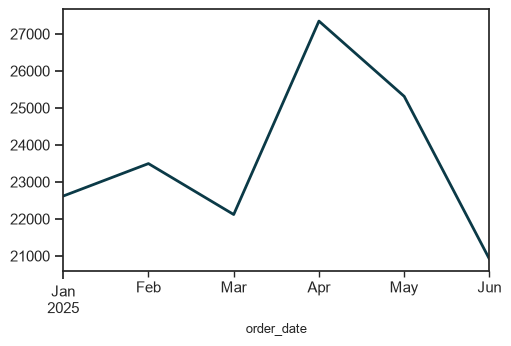

In [3]:
monthly = orders.set_index('order_date')['revenue'].resample('ME').sum()
monthly.plot()
plt.show()

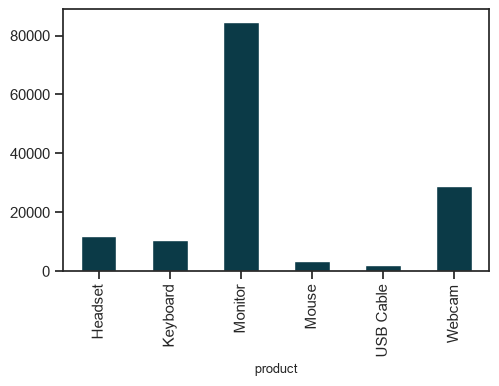

In [4]:
orders.groupby('product')['revenue'].sum().plot.bar()
plt.show()

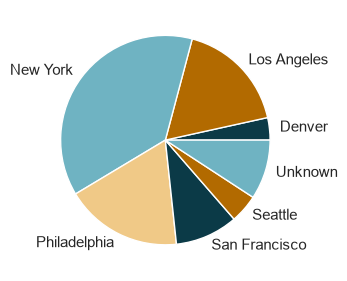

In [5]:
orders.groupby('city')['revenue'].sum().plot.pie()
plt.show()

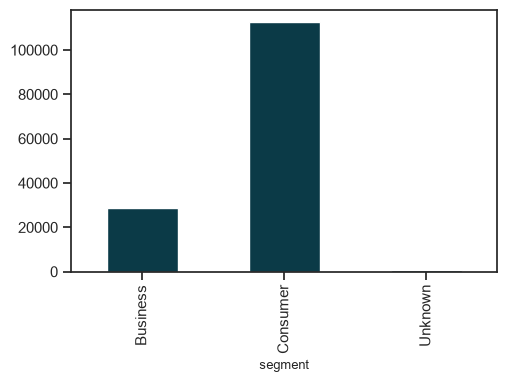

In [6]:
orders.groupby('segment')['revenue'].sum().plot.bar()
plt.show()

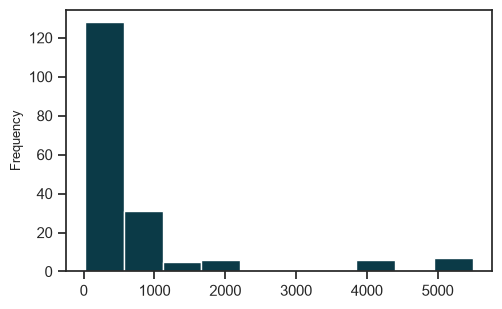

In [7]:
orders['revenue'].plot.hist()
plt.show()

## 18.3 The Polished Versions

In [8]:
total = orders['revenue'].sum()
by_product = (orders.groupby('product')['revenue'].sum()
              .sort_values(ascending=False))
by_city = (orders.groupby('city')['revenue'].sum()
           .sort_values(ascending=False))
no_city = by_city['Unknown']
by_city = by_city.drop('Unknown')
known_city = orders[orders['city'] != 'Unknown']
known = orders[orders['segment'] != 'Unknown']
by_segment = (known.groupby('segment')['revenue'].sum()
              .sort_values(ascending=False))

print(f'Total: ${total:,.0f} from {len(orders)} orders')
print(f'{by_product.index[0]}: {by_product.iloc[0] / total:.0%}')
print(f'{by_city.index[0]}: {by_city.iloc[0] / total:.0%}, '
      f'{by_city.iloc[0] / by_city.iloc[1]:.1f}x the next city')
print(f'Consumer: {by_segment["Consumer"] / by_segment.sum():.0%}')
print(f'No city: ${no_city:,.0f}')

Total: $141,809 from 184 orders
Monitor: 60%
New York: 38%, 2.1x the next city
Consumer: 80%
No city: $13,048


In [9]:
months = monthly.index.strftime('%b')
fall = 1 - monthly.iloc[-1] / monthly.max()
first, last = orders['order_date'].min(), orders['order_date'].max()
period = f'{first:%B} to {last:%B %Y}'

print(f'Period: {period}')
print(f'Best month: {monthly.idxmax():%B}, ${monthly.max():,.0f}')
print(f'June is {fall:.0%} below April')

Period: January to June 2025
Best month: April, $27,347
June is 24% below April


In [10]:
median, mean = orders['revenue'].median(), orders['revenue'].mean()
over = (orders['revenue'] > 2000).sum()
teal, amber, gray = '#0b3a47', '#b26a00', '#c4c9ce'

print(f'Median ${median:,.0f}, mean ${mean:,.0f}')
print(f'Orders over $2,000: {over}')

Median $259, mean $771
Orders over $2,000: 20


### Revenue by month

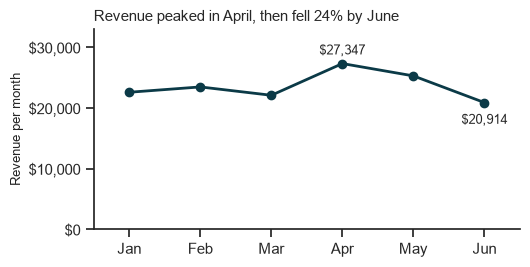

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 2.6))
ax.plot(months, monthly, marker='o')
ax.text(3, monthly.max() + 1500, f'${monthly.max():,.0f}',
        ha='center')
ax.text(5, monthly.iloc[-1] - 3500, f'${monthly.iloc[-1]:,.0f}',
        ha='center')
ax.set_ylim(0, 33000)
ax.margins(x=0.1)
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.set_title(f'Revenue peaked in April, then fell {fall:.0%} by June')
ax.set_ylabel('Revenue per month')
plt.show()

### Revenue by product

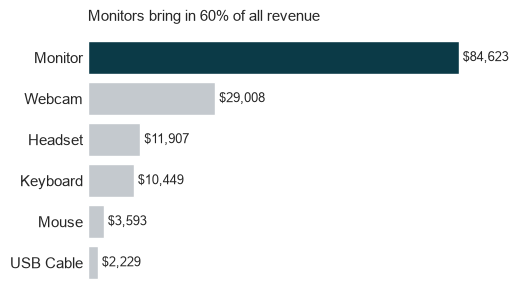

In [12]:
fig, ax = plt.subplots()
bars = ax.barh(by_product.index, by_product,
               color=[teal] + [gray] * 5)
ax.bar_label(bars, fmt='${:,.0f}', padding=3)
ax.invert_yaxis()
ax.margins(x=0.15)
ax.spines[:].set_visible(False)
ax.xaxis.set_visible(False)
ax.tick_params(axis='y', length=0)
ax.set_title(f'{by_product.index[0]}s bring in '
             f'{by_product.iloc[0] / total:.0%} of all revenue')
plt.show()

### Revenue by city

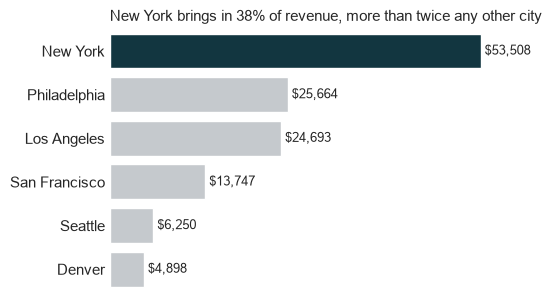

In [13]:
palette = {c: teal if c == 'New York' else gray for c in by_city.index}
ax = sns.barplot(data=known_city, y='city', x='revenue',
                 estimator='sum',
                 errorbar=None, order=by_city.index, hue='city',
                 palette=palette, legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='${:,.0f}', padding=3)
ax.margins(x=0.15)
sns.despine(left=True, bottom=True)
ax.xaxis.set_visible(False)
ax.tick_params(axis='y', length=0)
ax.set(ylabel='', title=f'{by_city.index[0]} brings in '
       f'{by_city.iloc[0] / total:.0%} of revenue, more than twice '
       'any other city')
plt.show()

### Consumers and businesses

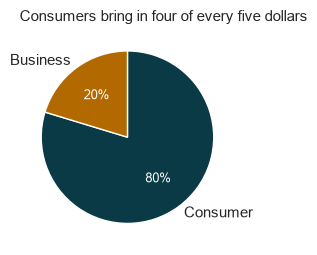

In [14]:
fig, ax = plt.subplots(figsize=(4, 2.8))
wedges, labels, pcts = ax.pie(
    by_segment, labels=by_segment.index, colors=[teal, amber],
    autopct='%1.0f%%', startangle=90, counterclock=False)
for pct in pcts:
    pct.set_color('white')
ax.set_title('Consumers bring in four of every five dollars')
plt.show()

### Order sizes

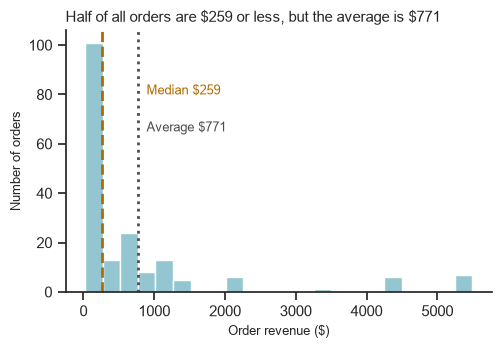

In [15]:
ax = sns.histplot(data=orders, x='revenue', binwidth=250,
                  color='#6fb3c2')
ax.axvline(median, color=amber, linestyle='--')
ax.axvline(mean, color='0.3', linestyle=':')
ax.text(mean + 120, 80, f'Median ${median:,.0f}', color=amber)
ax.text(mean + 120, 65, f'Average ${mean:,.0f}', color='0.3')
sns.despine()
ax.set(xlabel='Order revenue ($)', ylabel='Number of orders',
       title=f'Half of all orders are \\${median:,.0f} or less, '
             f'but the average is \\${mean:,.0f}')
plt.show()

## 18.4 One Page for the Manager

In [16]:
headline = (f'Sales, {period}: ${total:,.0f} '
            f'from {len(orders)} orders')
product_colors = [teal] + [gray] * 5

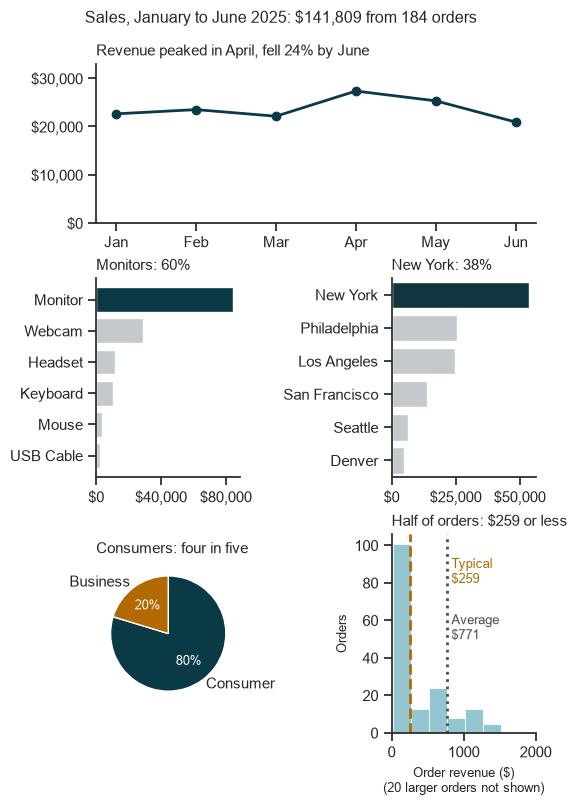

In [17]:
fig, axes = plt.subplot_mosaic('AA;BC;DE', figsize=(5.5, 7.6),
                               height_ratios=[0.8, 1, 1],
                               layout='constrained')

axes['A'].plot(months, monthly, marker='o')
axes['A'].set_ylim(0, 33000)
axes['A'].yaxis.set_major_formatter(
    StrMethodFormatter('${x:,.0f}'))
axes['A'].set_title(f'Revenue peaked in April, fell {fall:.0%} by June')

axes['B'].barh(by_product.index, by_product, color=product_colors)
axes['B'].invert_yaxis()
axes['B'].set_xticks([0, 40000, 80000])
axes['B'].xaxis.set_major_formatter(
    StrMethodFormatter('${x:,.0f}'))
axes['B'].set_title(f'Monitors: {by_product.iloc[0] / total:.0%}')

sns.barplot(data=known_city, y='city', x='revenue', estimator='sum',
            errorbar=None, order=by_city.index, hue='city',
            palette=palette, legend=False, ax=axes['C'])
axes['C'].set_xticks([0, 25000, 50000])
axes['C'].xaxis.set_major_formatter(
    StrMethodFormatter('${x:,.0f}'))
axes['C'].set(ylabel='', xlabel='',
              title=f'New York: {by_city.iloc[0] / total:.0%}')

wedges, labels, pcts = axes['D'].pie(
    by_segment, labels=by_segment.index, colors=[teal, amber],
    autopct='%1.0f%%', startangle=90, counterclock=False)
for pct in pcts:
    pct.set_color('white')
axes['D'].set_title('Consumers: four in five')

sns.histplot(data=orders, x='revenue', binwidth=250,
             color='#6fb3c2', ax=axes['E'])
axes['E'].set_xlim(0, 2000)
axes['E'].axvline(median, color=amber, linestyle='--')
axes['E'].axvline(mean, color='0.3', linestyle=':')
axes['E'].text(mean + 60, 80, f'Typical\n${median:,.0f}', color=amber)
axes['E'].text(mean + 60, 50, f'Average\n${mean:,.0f}', color='0.3')
note = f'Order revenue ($)\n({over} larger orders not shown)'
axes['E'].set(xlabel=note, ylabel='Orders',
              title=f'Half of orders: \\${median:,.0f} or less')

for name in 'ABCE':
    axes[name].spines[['top', 'right']].set_visible(False)
fig.suptitle(headline, y=1.04)
fig.savefig('sales_report.png', dpi=200, bbox_inches='tight')
plt.show()

## 18.5 An Interactive Version

In [18]:
orders['month'] = orders['order_date'].dt.strftime('%b')
known = orders[orders['segment'] != 'Unknown']
by_month = known.pivot_table(index='month', columns='segment',
                             values='revenue', aggfunc='sum')
by_month = by_month.reset_index()
bool((by_month['Consumer'] > by_month['Business']).all())

True

In [19]:
fig = px.bar(by_month, x='month', y=['Consumer', 'Business'],
             labels={'month': '', 'value': 'Revenue per month ($)',
                     'variable': ''},
             category_orders={'month': months.tolist()},
             template='simple_white',
             color_discrete_sequence=[teal, amber])
fig.update_layout(title='Consumers out-earned businesses every month',
                  yaxis_tickprefix='$', yaxis_tickformat=',',
                  width=600, height=390)
fig.write_html('sales_report.html')
fig.show()